# 01 从变量到一张数字表

## 1 让电脑替我们算一次位置

假设一个物体从 1 米处出发，每秒前进 2 米。到了第 3 秒，位置应当是 $1+2\times3=7$ 米。这一步心算很容易；如果表里有许多个时刻，就可以把相同的计算交给程序。

第一段代码把时间、速度、初始位置分别保存，再按这条规则算位置。`time_s = 3` 中，等号把右边的数交给左边的名字。名字也说明这个数在计算里做什么：time_s 存时间，position 存结果。

In [1]:
from support import ROOT, check, show, style

In [2]:
time_s = 3
speed = 2.0
initial_position = 1.0
position = speed * time_s + initial_position
print(position)
print(type(time_s), type(speed))

7.0
<class 'int'> <class 'float'>


第一行输出是 `7.0`，与心算一致。后两项告诉我们保存了哪种数：`int` 是整数，`float` 是浮点数，能够表示带小数的量。`type` 查看类型，`print` 显示结果。

`+ - * /` 分别做加、减、乘、除，`**` 做乘方，括号改变计算次序。Python 从上往下执行，所以算 position 时，前面三个名字都已经有值。把时间改为 4 后重新运行，这一组赋值和计算也会重新发生。

### 练习 py01：把计算规则写出来

时间改为 4 秒，其余相同。填写预测位置和位置的平方。

In [3]:
ex_py01_time = 4
ex_py01_position = None  # TODO
ex_py01_square = None    # TODO

In [4]:
# 填写上一格后，运行检查。
check("位置", ex_py01_position, 9)
check("位置的平方", ex_py01_square, 81)

待填写：位置


待填写：位置的平方


<details>
<summary>提示</summary>

先用 2 * 时间 + 1，再使用 ** 2。

</details>

<details>
<summary>参考答案</summary>

```python
ex_py01_position = 2 * ex_py01_time + 1
ex_py01_square = ex_py01_position ** 2
```

</details>

## 2 同一个名字可以保存新的值

表里多个数需要相加时，中间结果也要保存。`total = total + value` 的右边读取旧的 total，加上 value 后，将新结果存回同一个名字。`total += value` 是这一步的简写。

In [5]:
total = 0
total = total + 3
total += 5
print(total)
equal_to_eight = total == 8
print(equal_to_eight)

8
True


total 从 0 变成 3，又变成 8。最后的 `total == 8` 得到 `True`，表示比较成立。`=` 保存值，`==` 比较值；比较的另一个结果是 `False`。`< <= > >=` 也产生这种布尔值，后面可以据此保留某些测量行。

## 3 字符串给数字加上可读的名字

只有一串数时，还容易记住它们的含义。输出多次测量后，编号和单位也需要一起显示。引号包住的 `"run-A"` 是字符串；`f"...{变量}..."` 把变量的值插进文字。`:.2f` 指定显示两位小数，变量里仍保存原来的数值。

In [6]:
run_name = "run-A"
measured = 7.12
message = f"{run_name}: position = {measured:.2f} m"
print(message)
print("原始数值：", measured)

run-A: position = 7.12 m
原始数值： 7.12


## 4 列表把一串数放在一起

现在把四次位置读数放在一起。时刻是 0、1、2、3 秒，读数是 1.1、3.0、5.2、6.9 米；它们接近刚才的直线，却没有完全落在上面。

方括号建立列表，位置编号从 0 开始。`values[0]` 取第一个数，`values[-1]` 取最后一个数；`len(values)` 数元素个数。切片 `values[1:3]` 包含编号 1、2，遇到右端编号 3 就停止。

In [7]:
times = [0.0, 1.0, 2.0, 3.0]
positions = [1.1, 3.0, 5.2, 6.9]
print(times[0], positions[-1])
print(positions[1:3])
print("测量次数：", len(times))

0.0 6.9
[3.0, 5.2]
测量次数： 4


### 练习 py02：按编号取出测量值

取出第二次测量、最后两次测量，以及测量次数。

In [8]:
ex_py02_values = [1.1, 3.0, 5.2, 6.9]
ex_py02_second = None  # TODO
ex_py02_tail = None    # TODO
ex_py02_count = None   # TODO

In [9]:
# 填写上一格后，运行检查。
check("第二次测量", ex_py02_second, 3.0)
check("最后两次", ex_py02_tail, [5.2, 6.9])
check("次数", ex_py02_count, 4)

待填写：第二次测量
待填写：最后两次
待填写：次数


<details>
<summary>提示</summary>

第二次测量的编号是 1；最后两个数用 [-2:]；个数用 len。

</details>

<details>
<summary>参考答案</summary>

```python
ex_py02_second = ex_py02_values[1]
ex_py02_tail = ex_py02_values[-2:]
ex_py02_count = len(ex_py02_values)
```

</details>

## 5 循环把同一个动作交给每个元素

四次测量的平均位置可以用加法和除法求出。逐个手写加法仍然是在重复同一个动作：拿到一个读数，把它加入总和。

`for value in positions:` 将这个动作写成循环。value 依次接到四个读数，冒号后缩进的行跟着执行四次。缩进退回后，计算总和除以次数，此时四个数都已加入。

In [10]:
position_sum = 0.0
for value in positions:
    position_sum += value
    print("加入", value, "以后：", position_sum)
position_mean = position_sum / len(positions)
print("平均位置：", position_mean)

加入 1.1 以后： 1.1
加入 3.0 以后： 4.1
加入 5.2 以后： 9.3
加入 6.9 以后： 16.200000000000003
平均位置： 4.050000000000001


累加输出从 1.1、4.1、9.3 走到约 16.2，平均位置为 4.05。末尾多出的 `000000000000003` 来自浮点数的近似存储：像 1.1 这样的十进制小数，转成二进制时往往需要舍入。这几位尾数也会出现在后面的残差中。

### 练习 py03：用循环算平方和

列表中每个数先平方，再累加。不要直接写出最后答案。

In [11]:
ex_py03_values = [1., 2., 3.]
ex_py03_total = 0.0
for ex_py03_value in ex_py03_values:
    # TODO：累加平方
    pass

In [12]:
# 填写上一格后，运行检查。
check("平方和", ex_py03_total, 14.)

还需修改：平方和
你的结果： 0.0 
对照结果： 14.0


<details>
<summary>提示</summary>

循环体使用 total += value ** 2。

</details>

<details>
<summary>参考答案</summary>

```python
ex_py03_total = 0.0
for ex_py03_value in ex_py03_values:
    ex_py03_total += ex_py03_value ** 2
```

</details>

## 6 按编号处理两列数据

平均位置概括了这组读数落在哪里。要比较读数与运动规则，还需要给每个时刻算一次预测。相同编号的时间与位置属于同一次测量，因此用同一个 i 查询两列。

把运动规则记成 $p(t)=wt+b$：$t$ 是时间，$p$ 是预测位置，$w$ 是速度参数，$b$ 是初始位置参数。这一轮取 $w=2$、$b=1$。

`range(n)` 提供 0 到 n−1 的编号，`append` 把算出的一个结果加到列表末尾。循环结束时，就有了与观测逐行对应的一整列预测。

In [13]:
weight = 2.0
bias = 1.0
predictions = []
for i in range(len(times)):
    prediction = weight * times[i] + bias
    predictions.append(prediction)
    print(i, times[i], positions[i], prediction)
print("整列预测：", predictions)

0 0.0 1.1 1.0
1 1.0 3.0 3.0
2 2.0 5.2 5.0
3 3.0 6.9 7.0
整列预测： [1.0, 3.0, 5.0, 7.0]


### 练习 py04：生成一整列预测

对 0、2、4 秒分别预测位置，速度为 3，初始位置为 −1。

In [14]:
ex_py04_times = [0., 2., 4.]
ex_py04_predictions = []
for ex_py04_t in ex_py04_times:
    # TODO：算一次预测，再 append
    pass

In [15]:
# 填写上一格后，运行检查。
check("三次预测", ex_py04_predictions, [-1., 5., 11.])

还需修改：三次预测
你的结果： [] 
对照结果： [-1.0, 5.0, 11.0]


<details>
<summary>提示</summary>

先算 3 * t - 1，再用 predictions.append(...)。

</details>

<details>
<summary>参考答案</summary>

```python
ex_py04_predictions = []
for ex_py04_t in ex_py04_times:
    ex_py04_predictions.append(3 * ex_py04_t - 1)
```

</details>

## 7 条件决定哪些结果保留

预测列是 `[1,3,5,7]`。与读数相减，第 2 行偏高 0.2 米，第 3 行偏低 0.1 米；正负号保存了偏差方向。

记残差 $r_i=y_i-p_i$，$y_i$ 是观测，$p_i$ 是预测，i 编号测量。现在挑出绝对偏差超过 0.15 米的行。`abs(r_i)` 去掉方向，`if 条件:` 在条件成立时执行缩进内容，`else:` 处理其余行。

In [16]:
residuals = []
large_error_ids = []
for i in range(len(times)):
    residual = positions[i] - predictions[i]
    residuals.append(residual)
    if abs(residual) > 0.15:
        large_error_ids.append(i)
    else:
        print("阈值内的测量编号：", i)
print("残差：", residuals, "超过阈值：", large_error_ids)

阈值内的测量编号： 0
阈值内的测量编号： 1
阈值内的测量编号： 3
残差： [0.10000000000000009, 0.0, 0.20000000000000018, -0.09999999999999964] 超过阈值： [2]


### 练习 py05：筛出较大的误差

保留绝对值大于 0.1 的误差。正负误差都应检查。

In [17]:
ex_py05_errors = [0.2, 0.05, -0.3, 0.0]
ex_py05_selected = []
for ex_py05_error in ex_py05_errors:
    # TODO：判断，再 append
    pass

In [18]:
# 填写上一格后，运行检查。
check("筛出的误差", ex_py05_selected, [0.2, -0.3])

还需修改：筛出的误差
你的结果： [] 
对照结果： [0.2, -0.3]


<details>
<summary>提示</summary>

先 if abs(error) > 0.1，再在下一层缩进里 append 原始误差。

</details>

<details>
<summary>参考答案</summary>

```python
ex_py05_selected = []
for ex_py05_error in ex_py05_errors:
    if abs(ex_py05_error) > 0.1:
        ex_py05_selected.append(ex_py05_error)
```

</details>

## 8 字典让一行数据的各项有名字

筛选结果只留下编号 2，因为它的残差约为 0.2。到这里，每行已经有时间、读数和编号；如果再加测量批次、温度等信息，只靠“第几列”记含义会越来越费力。

字典给各项加上名字：花括号里，冒号左边是键，右边是值。`row["time"]` 直接取得时间。把多行字典放进列表，就形成了有列名的一张表。

In [19]:
rows = [{"name": "A", "time": 0., "position": 1.1},
        {"name": "B", "time": 1., "position": 3.0},
        {"name": "C", "time": 2., "position": 5.2},
        {"name": "D", "time": 3., "position": 6.9}]
print(rows[2])
for row in rows:
    print(row["name"], row["time"], row["position"])

{'name': 'C', 'time': 2.0, 'position': 5.2}
A 0.0 1.1
B 1.0 3.0
C 2.0 5.2
D 3.0 6.9


### 练习 py06：从字典读取输入并计算

读取一行的 time，用参数 weight 和 bias 预测位置，再计算观测减预测。

In [20]:
ex_py06_row = {"time": 2., "position": 5.2}
ex_py06_parameters = {"weight": 2., "bias": 1.}
ex_py06_prediction = None  # TODO
ex_py06_residual = None    # TODO

In [21]:
# 填写上一格后，运行检查。
check("预测", ex_py06_prediction, 5.)
check("残差", ex_py06_residual, 0.2)

待填写：预测
待填写：残差


<details>
<summary>提示</summary>

两个字典分别取参数与输入，预测后再与 row['position'] 相减。

</details>

<details>
<summary>参考答案</summary>

```python
ex_py06_prediction = ex_py06_parameters["weight"] * ex_py06_row["time"] + ex_py06_parameters["bias"]
ex_py06_residual = ex_py06_row["position"] - ex_py06_prediction
```

</details>

## 9 用一个数概括整张表的误差

阈值筛选给出需要查看的行。若要比较两组速度参数，则希望每次计算得到一个整体误差。直接把残差相加会让正负偏差抵消，平方后，每行都贡献一个非负数。

平方误差和记为 $E=\sum_{i=0}^{n-1}r_i^2$，n 是测量次数；平均平方误差为 $M=E/n$。这组残差约为 `[0.1,0,0.2,-0.1]`，所以 $E=0.01+0+0.04+0.01=0.06$，$M=0.015$。循环将这笔手算对整张表执行一次。

In [22]:
squared_error_sum = 0.0
for row in rows:
    predicted = weight * row["time"] + bias
    residual = row["position"] - predicted
    squared_error_sum += residual ** 2
mse = squared_error_sum / len(rows)
print("平方误差和：", squared_error_sum, "平均平方误差：", mse)

平方误差和： 0.06000000000000001 平均平方误差： 0.015000000000000003


### 练习 py07：独立计算平均平方误差

已有三个残差，先累加平方，再除以测量次数。

In [23]:
ex_py07_residuals = [0.1, -0.2, 0.3]
ex_py07_sum = 0.0
for ex_py07_r in ex_py07_residuals:
    # TODO
    pass
ex_py07_mse = None  # TODO

In [24]:
# 填写上一格后，运行检查。
check("平方误差和", ex_py07_sum, 0.14)
check("平均平方误差", ex_py07_mse, 0.14 / 3)

还需修改：平方误差和
你的结果： 0.0 
对照结果： 0.14
待填写：平均平方误差


<details>
<summary>提示</summary>

循环内 sum += r ** 2；循环外 mse = sum / len(residuals)。

</details>

<details>
<summary>参考答案</summary>

```python
ex_py07_sum = 0.0
for ex_py07_r in ex_py07_residuals:
    ex_py07_sum += ex_py07_r ** 2
ex_py07_mse = ex_py07_sum / len(ex_py07_residuals)
```

</details>

## 10 把数字与图对起来

一个整体误差隐藏了偏差发生的位置。把四个读数和预测画在同一坐标轴上，第 2 行的偏高就会直接出现在图里。

绘图库 Matplotlib 中，`plt.subplots` 建立图与坐标轴，`ax.scatter` 画观测点，`ax.plot` 按顺序连接预测。横轴是时间，纵轴是位置，同一时刻的竖直差正是刚算过的残差。

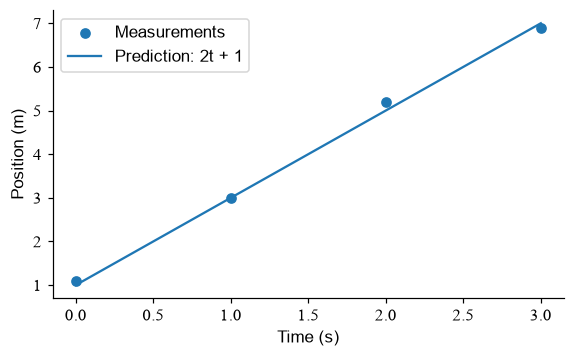

In [25]:
import matplotlib.pyplot as plt
style()
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.scatter(times, positions, label="Measurements")
ax.plot(times, predictions, label="Prediction: 2t + 1")
ax.set(xlabel="Time (s)", ylabel="Position (m)")
ax.legend()
show(fig)

## 把另一份读数交给程序

在新代码格里处理时间 `[0,1,2,3]`、位置 `[0.9,3.2,4.8,7.1]`。这一回把逐行预测、残差、整体误差与筛选接成一段程序。速度为 2、初始位置为 1 时，平均平方误差应为 0.025，绝对残差超过 0.15 的行编号为 1、2。

代码跑通后，将速度依次换成 1.8、2.0、2.2，保存三组误差。三次使用同一份读数，结果差别就可以追溯到速度参数。时刻与位置是给定的样本，速度与初始位置组成预测规则，误差由两者共同算出。

这已经是一次小型模型比较。下一课会把重复的预测和误差计算变成函数，让另一张表也能直接使用。

## 带着问题读原文

[Python 官方教程：基础语法与控制流](https://docs.python.org/3/tutorial/) 中的列表、for 和 if，已经在这张表的处理过程中出现过。读例子时，可以把其中的数换成自己的读数，观察一次缩进变化会让哪些行重复执行。